[![Obre a Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

# Nom i NIU

`Adrián Valverde Ambrosio` · `NIU: 1707952`

# Problema 3 · Classificació

> **Pregunta forta**
> Quan un número és prou fiable per decidir sobre una persona?

Treballareu amb `diabetes.csv` ([Pima Indians Diabetes](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database) de Kaggle), el mateix dataset de la sessió de hands-on. El target és `Outcome` (1 = diagnòstic positiu de diabetis). Un fals negatiu és un pacient malalt que marxa a casa sense seguiment; un fals positiu és una prova addicional. **No costen el mateix**, i la vostra entrega ho ha de reflectir.

## Com s'avalua (sobre 10)

| Exercici | Punts | Què es valora |
|---|---|---|
| Exercici 1 | 3 | Protocol honest: baseline, pipeline sense leakage, `C` triat amb validation |
| Exercici 2 | 3 | De la probabilitat a la decisió: llindar `τ` triat per cost, test una sola vegada |
| Exercici 3 | 2 | Desbalanceig: `KFold` vs `StratifiedKFold` i mètriques més enllà de l'accuracy |
| Exercici 4 | 2 | Auditoria per subgrup, Model Card i condició de no-ús |

No n'hi ha prou amb el codi: cada exercici es tanca amb una Decisió (evidència · risc · límit).

**Regla d'or de sempre (§7.4)**, la de Problemes 1. Aquesta setmana també hi entren la `C` i el llindar `τ`: es trien amb validation, mai amb test, i el test no torna a canviar cap decisió.

*Referències: llibre Tema 3 §3.1 (sigmoid, log-loss), §3.2.1 (mètriques), §3.2.2 (validació), §3.5.2 (escalat) i §7.4 (leakage).*

## Preparació de dades (comuna)

`diabetes.csv` ha d'estar al costat del notebook. Recordeu la lliçó de Problemes 1: **un 0 no sempre és un zero**. A `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` i `BMI`, el valor 0 és fisiològicament impossible i codifica un valor absent.

### Prediu abans d'executar
Si deixeu aquests zeros tal com estan i escaleu amb `StandardScaler`, què li passa a la mitjana i a la desviació de `Insulin`? En quina direcció es desplaçarà la frontera de decisió?

**Predicció:** a `Insulin` gairebé la meitat dels valors són 0 (374 de 768). Si es deixen, la **mitjana baixa** molt (el zero arrossega cap avall) i la **desviació** queda inflada per una massa de punts a 0 separada de la resta. Una insulina "normal" queda per sobre de la mitjana i sembla alta: la frontera de decisió es desplaça, i el model aprèn una relació falsa entre "insulina = 0" i el diagnòstic. Comprovació a la cel·la següent: mitjana 79.8 amb zeros contra 155.5 sense.

In [1]:
# Importació de llibreries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score, log_loss, classification_report)

RANDOM_STATE = 42

# Càrrega del dataset (diabetes.csv al costat del notebook)
df = pd.read_csv('diabetes.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
# Auditoria dels zeros impossibles: converteix-los en NaN abans de res
clinical_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df_audited = df.copy()
df_audited[clinical_cols] = df_audited[clinical_cols].replace(0, np.nan)
print('Zeros convertits en NaN:'); print(df_audited[clinical_cols].isna().sum())

# Comprovació de la predicció: Insulin amb zeros vs sense
print(f"\nInsulin amb zeros:  mitjana={df['Insulin'].mean():.1f}  desv={df['Insulin'].std():.1f}")
print(f"Insulin sense zeros: mitjana={df_audited['Insulin'].mean():.1f}  desv={df_audited['Insulin'].std():.1f}")

# Split train / validation / test estratificat 60/20/20 (les decisions es prenen amb validation)
X = df_audited.drop(columns='Outcome')
y = df_audited['Outcome']
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=RANDOM_STATE)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=RANDOM_STATE)
print(f'\ntrain {len(X_tr)} | validation {len(X_va)} | test {len(X_te)} | prevalença train {y_tr.mean():.3f}')

Zeros convertits en NaN:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Insulin amb zeros:  mitjana=79.8  desv=115.2
Insulin sense zeros: mitjana=155.5  desv=118.8

train 460 | validation 154 | test 154 | prevalença train 0.350


## Exercici 1 (3 punts) · Protocol honest

1. Entreneu una baseline obligatòria (`DummyClassifier`) i digueu quina accuracy obté. Aquest és el número que qualsevol model ha de superar per merèixer atenció.
2. Entreneu una regressió logística dins d'un `Pipeline` (imputació → escalat → model). Compareu-la amb la baseline.
3. Trieu el paràmetre de regularització `C` amb cross-validation estratificada sobre train (`StratifiedKFold`), no amb el test.
4. Reproduïu el **protocol incorrecte**: imputeu i escaleu amb *tot* `X` abans del split, i quantifiqueu la diferència respecte del protocol honest.

### Prediu abans d'executar
Abans de calcular res: el protocol amb leakage donarà una mètrica més alta, més baixa o igual? I aquesta diferència, és una millora del model o un error de mesura?

### Predicció (abans d'executar)
El protocol amb leakage donarà una mètrica **igual o una mica més alta**, mai una millora real: només ha "vist" la mediana i l'escala de validation. La diferència, si n'hi ha, és un **error de mesura**, no una millora del model. Amb un preprocessament tan simple (mediana i escalat) espero una diferència molt petita.

In [3]:
# Baseline obligatòria
dummy = DummyClassifier(strategy='most_frequent').fit(X_tr, y_tr)
print(f'Baseline (sempre "negatiu"): accuracy val = {dummy.score(X_va, y_va):.3f}')

# Pipeline honest: imputer + scaler + LogisticRegression
def make_pipe(C=1.0):
    return Pipeline([('imputer', SimpleImputer(strategy='median')),
                     ('scaler', StandardScaler()),
                     ('model', LogisticRegression(C=C, max_iter=1000))])

pipe = make_pipe().fit(X_tr, y_tr)
print(f'Logística (C=1): accuracy val = {pipe.score(X_va, y_va):.3f} | '
      f'AUC val = {roc_auc_score(y_va, pipe.predict_proba(X_va)[:, 1]):.3f}')

# Tria de C amb StratifiedKFold sobre train
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(make_pipe(), {'model__C': np.logspace(-3, 2, 11)}, cv=skf, scoring='roc_auc').fit(X_tr, y_tr)
C_best = grid.best_params_['model__C']
model = grid.best_estimator_                       # reajustat amb tot el train
p_va = model.predict_proba(X_va)[:, 1]
print(f'Millor C = {C_best:.3g} (AUC CV = {grid.best_score_:.3f})')
print(f'Model final: accuracy val = {model.score(X_va, y_va):.3f} | AUC val = {roc_auc_score(y_va, p_va):.3f}')

Baseline (sempre "negatiu"): accuracy val = 0.649
Logística (C=1): accuracy val = 0.753 | AUC val = 0.861


Millor C = 0.0316 (AUC CV = 0.832)
Model final: accuracy val = 0.747 | AUC val = 0.863


In [4]:
# Protocol INCORRECTE: imputer i scaler ajustats amb tot X abans del split
X_leak = StandardScaler().fit_transform(SimpleImputer(strategy='median').fit_transform(X))
X_leak = pd.DataFrame(X_leak, index=X.index)
lr_leak = LogisticRegression(C=C_best, max_iter=1000).fit(X_leak.loc[X_tr.index], y_tr)
p_va_leak = lr_leak.predict_proba(X_leak.loc[X_va.index])[:, 1]

# Quantifica la diferència entre els dos protocols
comp = pd.DataFrame({
    'honest': [model.score(X_va, y_va), roc_auc_score(y_va, p_va)],
    'leakage': [lr_leak.score(X_leak.loc[X_va.index], y_va), roc_auc_score(y_va, p_va_leak)]},
    index=['accuracy val', 'AUC val'])
comp['diferència'] = comp['leakage'] - comp['honest']
display(comp.round(4))

# Amb CV (5 folds) per veure-ho amb més mostres: honest (pipeline) vs preprocessat amb tot
cv_h = cross_val_score(make_pipe(C_best), X, y, cv=skf, scoring='roc_auc')
cv_l = cross_val_score(LogisticRegression(C=C_best, max_iter=1000), X_leak, y, cv=skf, scoring='roc_auc')
print(f'AUC CV honest = {cv_h.mean():.4f} ± {cv_h.std():.4f} | amb leakage = {cv_l.mean():.4f} ± {cv_l.std():.4f}')

,honest,leakage,diferència
accuracy val,0.7468,0.7403,-0.0065
AUC val,0.8631,0.8637,0.0006


AUC CV honest = 0.8356 ± 0.0221 | amb leakage = 0.8358 ± 0.0218


### Discussió · què ha canviat i per què

- **Baseline** (`DummyClassifier`, sempre negatiu): accuracy validation = **0.649** (la proporció de sanes).
- **Logística** dins del `Pipeline`: accuracy **0.747** i AUC **0.863** a validation: +10 punts d'accuracy sobre la baseline.
- **C triat** amb `GridSearchCV` + `StratifiedKFold(5)` sobre train, criteri AUC: **C = 0.0316** (AUC CV = 0.832). És una regularització força forta, però el resultat és quasi igual que C = 1 (AUC val 0.861): la logística amb 8 variables no sobreajusta gaire.
- **Protocol amb leakage:** accuracy −0.007 i AUC +0.0006 a validation; amb CV, 0.8358 contra 0.8356. La diferència és pràcticament **zero** i dins del soroll (desv. entre folds ≈ 0.02). Que aquí no "regali" gaire no vol dir que sigui correcte: amb preprocessaments que aprenen més de les dades (selecció de variables, target encoding, SMOTE) la diferència seria gran.

### Decisió (evidència · risc · límit)

- **Evidència:** el model supera clarament la baseline (0.747 vs 0.649) amb un protocol on imputació i escalat només veuen train, i C es tria amb CV dins de train.
- **Risc:** l'accuracy amaga el tipus d'error: amb τ = 0.5 deixa sense detectar 24 de 54 diabètiques a validation (recall 0.56). Validation només té 154 pacients.
- **Límit / no-ús:** l'accuracy no s'ha de fer servir per decidir res clínic; amb un altre preprocessament la comparació amb leakage s'ha de repetir.

## Exercici 2 (3 punts) · Quan es mou la política

El model retorna $h_\theta(x) = \sigma(z) \in (0,1)$, no una etiqueta. L'etiqueta apareix quan hi afegeixes un llindar `τ`, i el `τ` no surt de les dades: surt del cost que hi poses. A la sessió de hands-on el cost estava fixat (`FN` cinc vegades més car que `FP`). Aquí l'heu de qüestionar.

1. Obteniu les probabilitats de validation amb `predict_proba` i dibuixeu la seva distribució separada per classe real.
2. Construïu una funció que, donats `τ` i una raó de cost `FN:FP`, retorni TP, FP, FN, TN, precision, recall i el cost.
3. Per a cada raó de cost de 1 a 20, escombreu `τ` a validation i quedeu-vos amb el que minimitza el cost. Dibuixeu el `τ` triat contra la raó de cost.
4. Digueu on canvia el `τ` i en quin tram no es mou gens. Què vol dir, per a una discussió amb el servei, que un tram sencer de costos doni la mateixa decisió?
5. Trieu la raó que defensaríeu, apliqueu el seu `τ` al test **una sola vegada** i justifiqueu-la amb els FN i FP que genera, no amb una mètrica global.
6. Reporteu també la log-loss en validation i comenteu què penalitza que l'accuracy no veu.

### Prediu abans d'executar
Abans de dibuixar res: creieu que el `τ` baixarà de manera suau a mesura que `FN` es fa més car, o a salts? I creieu que hi haurà algun cost a partir del qual deixi de moure's?

### Predicció (abans d'executar)
Crec que el τ baixarà **a salts**, no de manera suau, perquè només tenim 154 pacients: el τ només canvia quan un FN més car fa que valgui la pena passar un altre grup de pacients a positiu. I crec que a partir d'un cost alt deixarà de moure's quan ja no quedin FN per evitar.

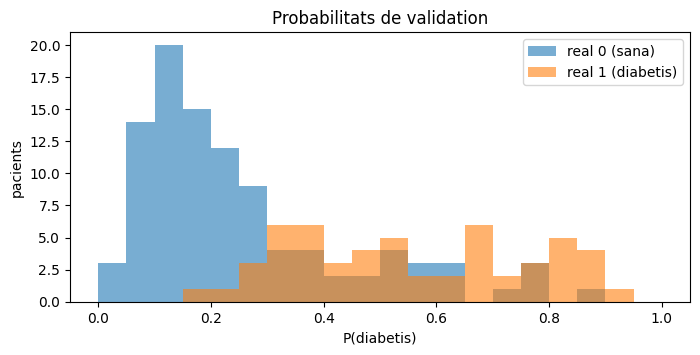

{'tau': 0.5, 'TP': np.int64(30), 'FP': np.int64(15), 'FN': np.int64(24), 'TN': np.int64(85), 'precision': np.float64(0.6666666666666666), 'recall': np.float64(0.5555555555555556), 'cost': np.int64(135)}


In [5]:
# Probabilitats en validation i distribució per classe real
plt.figure(figsize=(8, 3.5))
plt.hist(p_va[y_va == 0], bins=20, range=(0, 1), alpha=.6, label='real 0 (sana)')
plt.hist(p_va[y_va == 1], bins=20, range=(0, 1), alpha=.6, label='real 1 (diabetis)')
plt.xlabel('P(diabetis)'); plt.ylabel('pacients'); plt.legend(); plt.title('Probabilitats de validation'); plt.show()

# Funció d'avaluació per llindar i raó de cost (TP, FP, FN, TN, precision, recall, cost)
def avalua(y_true, proba, tau, ratio):
    pred = (proba >= tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {'tau': tau, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            'precision': tp / (tp + fp) if tp + fp else 0.0,
            'recall': tp / (tp + fn), 'cost': ratio * fn + fp}

print(avalua(y_va, p_va, 0.5, 5))

,tau,TP,FP,FN,TN,recall,precision,cost
ratio FN:FP,,,,,,,,
1,0.27,51.0,29.0,3.0,71.0,0.944,0.638,32.0
2,0.27,51.0,29.0,3.0,71.0,0.944,0.638,35.0
3,0.27,51.0,29.0,3.0,71.0,0.944,0.638,38.0
4,0.27,51.0,29.0,3.0,71.0,0.944,0.638,41.0
5,0.23,53.0,39.0,1.0,61.0,0.981,0.576,44.0
6,0.23,53.0,39.0,1.0,61.0,0.981,0.576,45.0
7,0.23,53.0,39.0,1.0,61.0,0.981,0.576,46.0
8,0.23,53.0,39.0,1.0,61.0,0.981,0.576,47.0
9,0.23,53.0,39.0,1.0,61.0,0.981,0.576,48.0


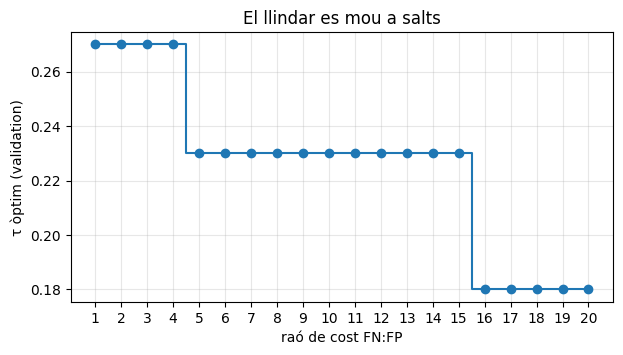

Raó 5:1 -> τ = 0.23
Test amb τ triat: {'tau': np.float64(0.23), 'TP': np.int64(47), 'FP': np.int64(53), 'FN': np.int64(6), 'TN': np.int64(48), 'precision': np.float64(0.47), 'recall': np.float64(0.8867924528301887), 'cost': np.int64(83)}
Test amb τ = 0.5: {'tau': 0.5, 'TP': np.int64(26), 'FP': np.int64(14), 'FN': np.int64(27), 'TN': np.int64(87), 'precision': np.float64(0.65), 'recall': np.float64(0.49056603773584906), 'cost': np.int64(149)}

Log-loss val model = 0.460 | log-loss baseline (prevalença) = 0.648


In [6]:
# Per a cada raó de cost d'1 a 20: escombrada de τ i tria del millor
taus = np.round(np.arange(0.01, 1.0, 0.01), 2)
files = []
for ratio in range(1, 21):
    res = pd.DataFrame([avalua(y_va, p_va, t, ratio) for t in taus])
    millor = res.loc[res['cost'].idxmin()]
    files.append({'ratio FN:FP': ratio, **millor.to_dict()})
tria = pd.DataFrame(files).set_index('ratio FN:FP')
display(tria[['tau', 'TP', 'FP', 'FN', 'TN', 'recall', 'precision', 'cost']].round(3))

# Figura: τ triat contra la raó de cost FN:FP
plt.figure(figsize=(7, 3.5))
plt.step(tria.index, tria['tau'], where='mid', marker='o')
plt.xlabel('raó de cost FN:FP'); plt.ylabel('τ òptim (validation)'); plt.xticks(range(1, 21)); plt.grid(alpha=.3)
plt.title('El llindar es mou a salts'); plt.show()

# Test final: una sola vegada, amb la raó que defenseu i el seu τ
RATIO = 5
TAU = tria.loc[RATIO, 'tau']
p_te = model.predict_proba(X_te)[:, 1]
print(f'Raó {RATIO}:1 -> τ = {TAU}')
print('Test amb τ triat:', avalua(y_te, p_te, TAU, RATIO))
print('Test amb τ = 0.5:', avalua(y_te, p_te, 0.5, RATIO))

# Log-loss en validation
print(f'\nLog-loss val model = {log_loss(y_va, p_va):.3f} | '
      f'log-loss baseline (prevalença) = {log_loss(y_va, np.full(len(y_va), y_tr.mean())):.3f}')

### Discussió · el llindar és una decisió, no un hiperparàmetre estètic

**On canvia τ:** només hi ha **tres valors**: τ = 0.27 per a raons 1-4, τ = 0.23 per a raons 5-15 i τ = 0.18 per a raons 16-20. Ja amb 1:1 surt un τ per sota de 0.5, perquè validation té més positius propers a la frontera. La predicció era correcta: es mou a salts.

**Trams on no es mou:** de 5 a 15 el τ és sempre 0.23 (1 FN, 39 FP). Per al servei això vol dir que **no cal posar-se d'acord en el cost exacte**: si tots estem d'acord que un FN costa "entre 5 i 15 FP", la decisió és la mateixa. La discussió s'ha de centrar només a les fronteres (4→5 i 15→16). A partir de 16 ja no queda cap FN a validation (recall = 1) i el τ no pot baixar més amb benefici.

**Raó triada: 5:1** (FN cinc vegades més car que FP, com a la sessió). Al **test (un sol cop)** amb τ = 0.23:
- τ = 0.23: **TP 47, FN 6, FP 53**, TN 48 → recall 0.89, precision 0.47, cost 83.
- τ = 0.5 (referència): TP 26, FN 27, FP 14 → recall 0.49, cost 149.

Respecte de 0.5, el τ triat **evita 21 FN** (21 diabètiques més amb seguiment) a canvi de **39 FP més** (39 proves addicionals). A la persona responsable li diria: "per cada diabètica que no enviem a casa, fem unes 2 proves extra".

Al test el recall (0.89) és més baix que a validation (0.98): el τ s'ha ajustat a validation i el test ho corregeix.

**Log-loss validation:** 0.460 contra 0.648 de la baseline (predir sempre la prevalença). La log-loss penalitza les probabilitats **segures i equivocades** (p. ex. dir 0.05 a una diabètica). L'accuracy només mira si s'està a un costat o a l'altre del 0.5 i no veu la confiança.

### Decisió (evidència · risc · límit)

- **Evidència:** τ = 0.23 minimitza el cost a validation per a tot el tram 5-15, i a test redueix el cost de 149 a 83 i els FN de 27 a 6.
- **Risc:** hi ha moltes proves addicionals (53 FP de 101 negatives). El τ s'ha triat amb 154 pacients i 54 positives; un sol pacient canvia l'òptim.
- **Límit / no-ús:** si les proves addicionals són invasives o escasses (cost FP alt), el τ s'ha de tornar a calcular. No val per a una població amb una prevalença diferent (35% aquí).

## Exercici 3 (2 punts) · Desbalanceig i mètriques

El codi següent força un dataset fortament desbalancejat eliminant part dels positius.

1. Apliqueu cross-validation al dataset desbalancejat amb i sense `StratifiedKFold` i compareu la variabilitat de la mètrica entre folds.
2. Analitzeu l'efecte de l'estratificació sobre la cerca del millor `C` (`GridSearchCV`).
3. Mostreu les corbes ROC i precision-recall i comenteu quina de les dues és més informativa quan la classe positiva és minoritària. Compareu l'average precision amb la prevalença del conjunt, que és el que trauria un classificador a l'atzar: una AP només es pot llegir sabent contra què competeix.

### Prediu abans d'executar
Amb un 14% de positius, quina accuracy obté un model que digui sempre "negatiu"? Aquest número, és bo?

### Predicció (abans d'executar)
Amb un 14% de positius, dir sempre "negatiu" dona una **accuracy del 86%**. Sembla un bon número però no detecta cap malalta (recall 0): no és bo, només reflecteix el desbalanceig.

In [7]:
# Forcem un dataset desbalancejat (fixa la llavor per poder reproduir-ho)
rng = np.random.default_rng(RANDOM_STATE)
candidates = np.where(df['Outcome'].values == 1)[0]
ids_to_remove = rng.choice(candidates, int(0.7 * len(candidates)), replace=False)

print('Abans del desbalanceig:', round(df['Outcome'].mean(), 4))
df_unbalanced = df.drop(df.index[ids_to_remove], axis=0)
print('Després del desbalanceig:', round(df_unbalanced['Outcome'].mean(), 4))

Abans del desbalanceig: 0.349
Després del desbalanceig: 0.1394


In [8]:
# Cross-validation amb KFold vs StratifiedKFold sobre el dataset desbalancejat
dfu = df_unbalanced.copy()
dfu[clinical_cols] = dfu[clinical_cols].replace(0, np.nan)
Xu, yu = dfu.drop(columns='Outcome'), dfu['Outcome']

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for nom, cv in [('KFold', kf), ('StratifiedKFold', skf)]:
    pos = [yu.iloc[te].sum() for _, te in cv.split(Xu, yu)]
    auc = cross_val_score(make_pipe(C_best), Xu, yu, cv=cv, scoring='roc_auc')
    ap = cross_val_score(make_pipe(C_best), Xu, yu, cv=cv, scoring='average_precision')
    print(f'{nom:16s} positius per fold: {pos} | AUC = {auc.mean():.3f} ± {auc.std():.3f} | '
          f'AP = {ap.mean():.3f} ± {ap.std():.3f}')

# Efecte de l'estratificació sobre GridSearchCV (millor C)
for nom, cv in [('KFold', kf), ('StratifiedKFold', skf)]:
    for seed in [0, 1, 2]:
        cv.random_state = seed
        g = GridSearchCV(make_pipe(), {'model__C': np.logspace(-3, 2, 11)}, cv=cv,
                         scoring='average_precision').fit(Xu, yu)
        print(f'{nom:16s} llavor {seed}: millor C = {g.best_params_["model__C"]:.3g}  (AP CV = {g.best_score_:.3f})')
kf.random_state = skf.random_state = RANDOM_STATE

KFold            positius per fold: [np.int64(13), np.int64(13), np.int64(21), np.int64(14), np.int64(20)] | AUC = 0.849 ± 0.053 | AP = 0.499 ± 0.134


StratifiedKFold  positius per fold: [np.int64(17), np.int64(16), np.int64(16), np.int64(16), np.int64(16)] | AUC = 0.848 ± 0.030 | AP = 0.472 ± 0.071


KFold            llavor 0: millor C = 31.6  (AP CV = 0.501)


KFold            llavor 1: millor C = 100  (AP CV = 0.480)


KFold            llavor 2: millor C = 1  (AP CV = 0.521)


StratifiedKFold  llavor 0: millor C = 0.1  (AP CV = 0.501)


StratifiedKFold  llavor 1: millor C = 3.16  (AP CV = 0.526)


StratifiedKFold  llavor 2: millor C = 0.1  (AP CV = 0.510)


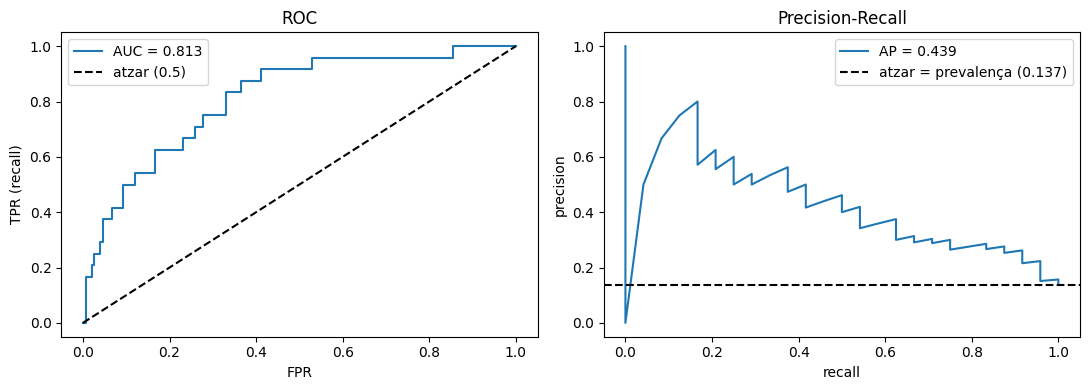

AUC = 0.813 (atzar 0.5) | AP = 0.439 (atzar 0.137)
Accuracy de dir sempre "negatiu": 0.863


In [9]:
# Corbes ROC i precision-recall (amb AUC i average precision)
Xu_tr, Xu_te, yu_tr, yu_te = train_test_split(Xu, yu, test_size=0.3, stratify=yu, random_state=RANDOM_STATE)
pu = make_pipe(C_best).fit(Xu_tr, yu_tr).predict_proba(Xu_te)[:, 1]
fpr, tpr, _ = roc_curve(yu_te, pu)
prec, rec, _ = precision_recall_curve(yu_te, pu)
prev = yu_te.mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(fpr, tpr, label=f'AUC = {roc_auc_score(yu_te, pu):.3f}')
axes[0].plot([0, 1], [0, 1], 'k--', label='atzar (0.5)')
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR (recall)'); axes[0].set_title('ROC'); axes[0].legend()
axes[1].plot(rec, prec, label=f'AP = {average_precision_score(yu_te, pu):.3f}')
axes[1].axhline(prev, color='k', ls='--', label=f'atzar = prevalença ({prev:.3f})')
axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision'); axes[1].set_title('Precision-Recall'); axes[1].legend()
plt.tight_layout(); plt.show()
print(f'AUC = {roc_auc_score(yu_te, pu):.3f} (atzar 0.5) | AP = {average_precision_score(yu_te, pu):.3f} (atzar {prev:.3f})')
print(f'Accuracy de dir sempre "negatiu": {1 - prev:.3f}')

### Discussió · quina mètrica sobreviu al desbalanceig

**KFold vs StratifiedKFold** (dataset amb 13.9% de positius, 81 positius):
| | positius per fold | AUC | AP |
|---|---|---|---|
| KFold | 13, 13, 21, 14, 20 | 0.849 ± 0.053 | 0.499 ± 0.134 |
| StratifiedKFold | 17, 16, 16, 16, 16 | 0.848 ± 0.030 | 0.472 ± 0.071 |

La mitjana és pràcticament la mateixa, però amb KFold la **desviació entre folds és quasi el doble** (AUC 0.053 vs 0.030, AP 0.134 vs 0.071), perquè cada fold té un nombre de positius diferent (13 a 21). L'estratificació no millora el model: fa la **mesura més estable**.

**Efecte sobre GridSearchCV:** amb KFold el millor C canvia molt amb la llavor (31.6, 100, 1); amb StratifiedKFold és més estable (0.1, 3.16, 0.1). Amb la mateixa dada, el soroll de KFold fa que la tria de C sigui quasi aleatòria.

**ROC vs PR:** AUC = 0.813 (atzar = 0.5) i AP = 0.439 (atzar = prevalença = 0.137). La ROC sembla bona perquè l'FPR es calcula sobre moltes negatives i els FP hi pesen poc. La **PR és més informativa**: mostra que, per detectar la majoria de positives, la precision cau per sota del 40%. Una AP de 0.44 és **3.2 vegades millor que l'atzar**, però no vol dir el mateix que un 0.44 amb classes balancejades.

### Decisió (evidència · risc · límit)

- **Evidència:** amb classe minoritària, faig servir **StratifiedKFold** (desv. la meitat) i reporto **AP comparada amb la prevalença**, a més de l'AUC.
- **Risc:** amb 81 positius, cada fold en té 16: les mètriques segueixen tenint molta variància (AP ± 0.07).
- **Límit / no-ús:** l'AP no es pot comparar entre poblacions amb prevalences diferents; l'accuracy no s'ha de reportar sola mai amb dades desbalancejades.

## Exercici 4 (2 punts) · Auditoria, límits i Model Card

1. **Auditoria per subgrup:** a classe l'auditoria es va fer per edat. Feu-la ara per nombre d'embarassos, `Pregnancies`, amb els grups `0`, `1-3` i `4 o més`. Reporteu recall i precision de cada grup amb el vostre `τ`, i digueu explícitament quantes pacients hi ha a cada grup abans d'interpretar cap diferència.
2. **Abans de concloure res:** mireu també quina proporció de positives té cada grup. Si la precision no és igual a tots, decidiu si és perquè el model hi va pitjor o perquè la prevalença hi és diferent, i digueu com ho distingiu.
3. **Calibratge:** comproveu amb `calibration_curve` si una probabilitat de 0.8 correspon aproximadament a un 80% de casos positius, i comenteu què implica si no és així.
4. **Condició de no-ús:** enuncieu almenys una situació concreta en què aquest model no s'hauria de desplegar. Penseu en la població d'origen del dataset (dones d'ascendència pima, de 21 anys o més) i en què passa si el desplegueu sobre una població diferent.

### Pregunta per raonar
Si el recall del grup `4 o més` fos 0.75 i el del grup `0` fos 0.50, tindríeu prou evidència per afirmar que el model tracta pitjor les pacients sense embarassos? Què necessitaríeu per afirmar-ho?

### Pregunta per raonar
**No.** Amb el grup `0` tenim només 30 pacients al test i **8 positives**: un recall de 0.50 vol dir 4 de 8, i un recall de 0.75 voldria dir 6 de 8. Un sol pacient mou el recall 12.5 punts. Per afirmar-ho necessitaríem: més pacients a cada grup (o intervals de confiança, p. ex. bootstrap, que no se solapin), comprovar que la diferència es manté amb diferents splits, i descartar que la diferència sigui de prevalença o d'altres variables (les dones amb 0 embarassos són més joves, i l'edat pesa al model).

Test


,pacients,positives reals,prevalença,recall,precision
grup,,,,,
0,30.0,8.0,0.267,0.750,0.353
1-3,59.0,18.0,0.305,0.833,0.517
4 o més,65.0,27.0,0.415,0.963,0.481


Validation + test


,pacients,positives reals,prevalença,recall,precision
grup,,,,,
0,49.0,11.0,0.224,0.818,0.346
1-3,125.0,39.0,0.312,0.923,0.571
4 o més,134.0,57.0,0.425,0.965,0.534


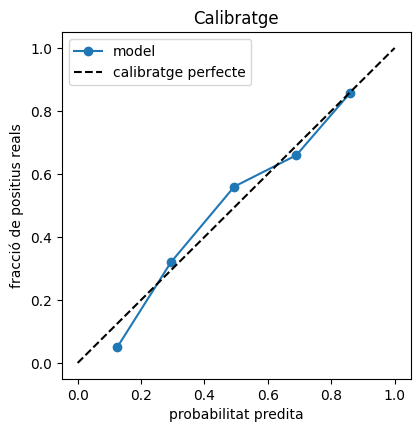

   probabilitat mitjana  fracció positius
0                 0.125             0.050
1                 0.294             0.320
2                 0.494             0.560
3                 0.690             0.660
4                 0.859             0.857


In [10]:
# Auditoria per subgrup (mida del grup + proporció de positives + recall + precision)
# Sobre el test, amb el model i el τ ja fixats (no es canvia cap decisió).
# Com que el test té pocs casos, també ho mirem a validation + test.
from sklearn.calibration import calibration_curve

def grup(p):
    return pd.cut(p, [-1, 0, 3, 100], labels=['0', '1-3', '4 o més'])

def auditoria(Xs, ys, ps):
    pred = (ps >= TAU).astype(int)
    d = pd.DataFrame({'grup': grup(Xs['Pregnancies']), 'y': ys.values, 'pred': pred})
    return d.groupby('grup', observed=True).apply(lambda g: pd.Series({
        'pacients': len(g), 'positives reals': int(g['y'].sum()), 'prevalença': g['y'].mean(),
        'recall': recall_score(g['y'], g['pred'], zero_division=0),
        'precision': precision_score(g['y'], g['pred'], zero_division=0)}), include_groups=False)

print('Test'); display(auditoria(X_te, y_te, p_te).round(3))
print('Validation + test')
display(auditoria(pd.concat([X_va, X_te]), pd.concat([y_va, y_te]), np.r_[p_va, p_te]).round(3))

# Corba de calibratge (validation + test, 5 trams)
frac_pos, mean_pred = calibration_curve(np.r_[y_va, y_te], np.r_[p_va, p_te], n_bins=5)
plt.figure(figsize=(4.5, 4.5))
plt.plot(mean_pred, frac_pos, 'o-', label='model'); plt.plot([0, 1], [0, 1], 'k--', label='calibratge perfecte')
plt.xlabel('probabilitat predita'); plt.ylabel('fracció de positius reals'); plt.legend(); plt.title('Calibratge'); plt.show()
print(pd.DataFrame({'probabilitat mitjana': mean_pred, 'fracció positius': frac_pos}).round(3))

### Discussió · què no pots afirmar amb aquestes dades

**Auditoria** (τ = 0.23; model i τ fixats abans de mirar els grups):

| grup | pacients (test) | positives | prevalença | recall | precision |
|---|---|---|---|---|---|
| 0 | 30 | 8 | 0.27 | 0.75 | 0.35 |
| 1-3 | 59 | 18 | 0.31 | 0.83 | 0.52 |
| 4 o més | 65 | 27 | 0.42 | 0.96 | 0.48 |

El patró es manté amb validation + test (recall 0.82 / 0.92 / 0.97, precision 0.35 / 0.57 / 0.53), però el grup `0` continua tenint només 11 positives.

**Prevalença vs model:** la precision més baixa del grup `0` s'explica en bona part per la **prevalença**: hi ha menys positives (22-27%), i amb el mateix τ una part més gran dels positius predits són FP. Per distingir-ho miraria mètriques que no depenen de la prevalença (recall i taxa de FP per grup, o l'AUC per grup): si el recall i l'FPR fossin iguals, la diferència de precision seria només de prevalença. Aquí el recall també és més baix al grup `0`, però amb 8 positives la diferència no és significativa.

**Calibratge:** quan el model diu 0.86, la fracció de positives és 0.86; a 0.69 és 0.66; a 0.49 és 0.56. Està **raonablement calibrat** (la regularització forta ajuda). Els trams baixos són els pitjors (0.125 predit vs 0.05 real). Si no estigués calibrat, no podríem llegir la sortida com a "risc del 80%" davant d'una pacient, i el τ triat per cost deixaria de ser vàlid si la probabilitat es desplacés.

### Decisió (evidència · risc · límit)

- **Evidència:** recall ≥ 0.75 a tots els grups, i probabilitats ben calibrades a la zona alta.
- **Risc:** grups petits (8 positives al grup `0`): no podem afirmar ni descartar diferències de tracte.
- **Límit / no-ús:** **no desplegar-lo sobre una població diferent de dones d'ascendència pima de 21 anys o més** (homes, menors, altres ètnies): la prevalença de diabetis tipus 2 dels pima és de les més altes del món, i el model (i el τ) donaria massa positius en una població general, a més de no saber com es comporta per a variables com `Pregnancies` que en homes no existeix.

## Mini Model Card (lliurable final)

| Camp | Resposta |
|---|---|
| Ús previst | Cribratge: decidir quines pacients necessiten una prova addicional de diabetis. No és un diagnòstic. |
| Què representa cada fila? | Una pacient amb 8 mesures clíniques. |
| Població d'origen (qui hi ha i qui no hi és) | Dones d'ascendència pima, ≥ 21 anys (Arizona). No hi ha homes, menors ni altres ètnies. |
| Target `y` i prevalença | `Outcome` (1 = diabetis), prevalença 34.9%. |
| Tractament dels zeros impossibles | 0 → NaN a `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`; imputació per mediana dins del pipeline. |
| Preparació sense leakage (què s'ajusta i amb què) | `SimpleImputer` i `StandardScaler` dins del `Pipeline`, ajustats només amb train (i amb cada fold de train a la CV). |
| Model i `C` triat, amb quin criteri | Regressió logística, C = 0.0316, millor AUC amb `StratifiedKFold(5)` a train. |
| Llindar `τ` i cost que minimitza | τ = 0.23, minimitza 5·FN + FP a validation (val per a raons de 5 a 15). |
| Mètrica principal i per què | Cost (5·FN + FP) i recall: el FN és l'error car. AUC/AP per comparar models. |
| Error més crític (FP o FN) i per què | FN: una malalta que marxa a casa sense seguiment. Un FP és una prova extra. |
| Resultat en test (una sola lectura) | τ = 0.23: recall 0.89, precision 0.47, 6 FN, 53 FP, cost 83 (149 amb τ = 0.5). |
| Condició de no-ús | No desplegar en poblacions diferents (homes, altres ètnies, menors de 21) ni amb una prevalença diferent sense recalcular τ. |

## Declaració d'ús d'IA (obligatòria, no puntua)

| | La vostra resposta |
|---|---|
| Quina eina heu fet servir | Claude (Anthropic), assistent de programació. |
| Per a què exactament | Proposta i redacció del codi (pipeline, escombrat de τ, CV, auditoria) i esborrany dels textos. |
| Com heu verificat el que us ha donat | Executant el notebook i comprovant que els números del text coincideixen amb les sortides; revisant que C i τ es trien sense test i que el test s'obre un sol cop. |
| Què heu decidit vosaltres | La raó de cost 5:1 i el τ, la mètrica principal i la condició de no-ús. |
| Què no heu delegat | La revisió final i la defensa de les decisions. |

## Autoavaluació (opcional) · no compta per nota

Eina de teaching per situar-vos (rúbrica del curs). Objectiu personal: 8/8 i cap zero.

| Criteri | 2 | 1 | 0 |
|---|---|---|---|
| **Concepte** | connecto score, sigmoid, log-loss i llindar | només defineixo termes | els confonc |
| **Protocol** | tot `fit` només amb train; test llegit una vegada | parcial | leakage / trio amb test |
| **Interpretació** | dono significat a probabilitats, corbes i errors | només descric la sortida | només un número |
| **Decisió** | evidència + risc + condició de no-ús | incompleta | no defensable |

## Frase final

*Un model no es defensa amb el número més alt, sinó amb el protocol que l'ha produït i amb els errors que ha decidit acceptar.*